# ICT-15d — Cochaîne de Čech pondérée : obstruction intra-substrat

**Issue** : [#7744](https://github.com/jsboige/CoursIA/issues/7744) (jambe transverse #7395/#4588).
**Module outillant le notebook** : `ict.cech_obstruction` (PR #8828 MERGED `feat/ict-cech-obstruction-7744`).
**Requis ICT-15c** : ce notebook complète l'échelle ICT-15 (Integrated Complexity, strate 5) en passant
de la **comparaison entre substrats** (Phase Zéro, `ict.meta_proxy`, ICT-15c) à la **structure
relationnelle intra-substrat** : rangs, résidus de transport, holonomie cyclique.

## Diagnostic ferme (audit tour 369, cf issue #7744)

`ict.meta_proxy` ("Phase Zéro") détecte la **dispersion des signatures entre substrats** : il compare
les niveaux bruts (gap spectral, sensibilité moyenne/max) *d'un substrat à l'autre*. Le diagnostic est
que ce n'est pas une obstruction : comparer des niveaux bruts (même normalisés) mesure un écart
d'échelle, pas un *motif de désaccord structurel*.

Ce notebook applique la **cochaîne de Čech pondérée** (`ict.cech_obstruction`) pour répondre à la question
fine : *sur un seul substrat, est-ce que plusieurs proxys se "recollent" en une mesure globale unique ?*

## Objet mathématique : la cochaîne de Čech pondérée

On découpe la trajectoire d'un substrat en fenêtres contiguës. Chaque proxy devient une **section
locale** (sa valeur scalaire par fenêtre). Sur ces sections :

| Objet Čech | Ici | Signification |
|---|---|---|
| **Recouvrement double** (cobord, 1-cochaîne) | `transport_residual(s_i, s_j)` | résidu post-ajustement affine ; absorbé si purement affine |
| **Recouvrement triple** (cocycle, 2-cochaîne) | `holonomy(r_ij, r_jk, r_ki)` | somme cyclique des résidus ; non-nulle = désaccord cyclique |
| **Non-nullité de la classe** | `mean_cocycle` (cocycle triple) | cocycle nul = proxys recollables (trivial) vs non nul = obstruction |

**Verdict falsifiable** : `NON_TRIVIAL` si le cocycle triple (`mean_cocycle`) dépasse un plancher ET que les
holonomies portent une direction majoritaire (`sign_consistency` ≥ 0.5). `TRIVIAL` si le cocycle est nul.
`INCONCLUSIVE` si moins de 3 proxys, ou cocycle non nul sans direction. La dimensionnalité SVD reste
rapportée comme témoin : elle ne décide plus.

## Acceptance (#7744)

**Positif** : sur ≥ 1 substrat ICT, la lecture-obstruction **change une décision expérimentale ou une
visualisation** (ex : reclasser un régime "dispersion" en régime "obstruction", ou disqualifier un proxy).

**Négatif honnête** : sur tous les substrats, les proxys se réduisent à un signal latent 1D — 
échec du candidat à constater une obstruction, la jambe transverse meurt proprement.

## Substrats

Mêmes substrats qu'ICT-15c : **Gray-Scott** (Turing), **Axelrod** (réplicateur), **Grokking** (compression
crossover), **May** (ICT-8, pâturage bistable). Déterministes (seeds fixés).


> **Statut épistémique** — **Spéculatif** : La cochaîne de Čech pondérée discriminate les substrats (`NON_TRIVIAL` = les proxys ne se recollent pas en 1D). Portée et détail dans la [matrice de dissociations](../../../../docs/ict/dissociations-matrix.md).

In [1]:
# Imports et setup
import sys
from pathlib import Path
import numpy as np

ICT_ROOT = Path('.').resolve()
if str(ICT_ROOT) not in sys.path:
    sys.path.insert(0, str(ICT_ROOT))

from ict import cech_obstruction as CO
from ict import spectral as SP
from ict import sensitivity as SE
from ict import meta_proxy as MP

print("ict.cech_obstruction charg\u00e9. Fonctions publiques :")
for fn in ['proxy_sections', 'normalize_sections', 'effective_dimensionality',
          'transport_residual', 'holonomy', 'cech_obstruction_class',
          'cech_obstruction_verdict', 'cech_obstruction_test']:
    print(f"  - {fn}")

# Helper : wrap un proxy callable pour proxy_sections (même signature que MP.ProxyFn).
def spec_gap_wrap(states, n_symbols):
    return float(SP.spectral_summary(states, n_symbols)['spectral_gap'])

def sens_mean_wrap(states, n_symbols):
    f = lambda x: x  # identité sur le vocabulaire ordinal (cf L932 desaturation)
    return float(SE.sensitivity_distribution(states, n_symbols, f)['mean'])

def sens_max_wrap(states, n_symbols):
    f = lambda x: x
    return float(SE.sensitivity_distribution(states, n_symbols, f)['max'])

PROXIES = {
    "spectral_gap": spec_gap_wrap,
    "sens_mean": sens_mean_wrap,
    "sens_max": sens_max_wrap,
}
print(f"\n{len(PROXIES)} proxys d\u00e9finis : {list(PROXIES.keys())}")


ict.cech_obstruction chargé. Fonctions publiques :
  - proxy_sections
  - normalize_sections
  - effective_dimensionality
  - transport_residual
  - holonomy
  - cech_obstruction_class
  - cech_obstruction_verdict
  - cech_obstruction_test

3 proxys définis : ['spectral_gap', 'sens_mean', 'sens_max']


In [2]:
# Sanity check : reproduction du banc interne cech_obstruction_test
# Affirme : banc affine -> TRIVIAL, banc multi-dim -> NON_TRIVIAL.
# Si cette discrimination échoue, l'instrument n'est pas capable de rendre
# le verdict positif sur les substrats réels (cf Prong B sota-not-workaround).
results = []
for seed in range(8):
    r = CO.cech_obstruction_test(n_windows=60, seed=seed)
    results.append(r)
    print(f"seed={seed}: affine_verdict={r['affine_verdict']:>10s} "
          f"(cocycle={r['affine_cocycle']:.4f}, s2/s1={r['affine_s2_over_s1']:.3f}) | "
          f"multi_verdict={r['multi_verdict']:>11s} "
          f"(cocycle={r['multi_cocycle']:.4f}, sign={r['multi_sign_consistency']:.4f}, "
          f"s2/s1={r['multi_s2_over_s1']:.3f}, rank={r['multi_effective_rank']}) | "
          f"passes={r['passes']}")
passes_total = sum(r['passes'] for r in results)
print(f"\nBanc synth\u00e9tique : {int(passes_total)}/8 seeds passent (TRIVIAL + NON_TRIVIAL discrimin\u00e9s).")
assert passes_total == 8, "Le banc interne doit passer 8/8 sur signaux synth\u00e9tiques."


seed=0: affine_verdict=   TRIVIAL (cocycle=0.0000, s2/s1=0.000) | multi_verdict=NON_TRIVIAL (cocycle=1.0251, sign=0.5500, s2/s1=0.713, rank=2) | passes=1.0
seed=1: affine_verdict=   TRIVIAL (cocycle=0.0000, s2/s1=0.000) | multi_verdict=NON_TRIVIAL (cocycle=0.8862, sign=0.5000, s2/s1=0.687, rank=2) | passes=1.0
seed=2: affine_verdict=   TRIVIAL (cocycle=0.0000, s2/s1=0.000) | multi_verdict=NON_TRIVIAL (cocycle=1.0717, sign=0.5000, s2/s1=0.718, rank=2) | passes=1.0
seed=3: affine_verdict=   TRIVIAL (cocycle=0.0000, s2/s1=0.000) | multi_verdict=NON_TRIVIAL (cocycle=1.1310, sign=0.5500, s2/s1=0.737, rank=2) | passes=1.0
seed=4: affine_verdict=   TRIVIAL (cocycle=0.0000, s2/s1=0.000) | multi_verdict=NON_TRIVIAL (cocycle=0.9561, sign=0.5333, s2/s1=0.693, rank=2) | passes=1.0
seed=5: affine_verdict=   TRIVIAL (cocycle=0.0000, s2/s1=0.000) | multi_verdict=NON_TRIVIAL (cocycle=1.1644, sign=0.5167, s2/s1=0.857, rank=2) | passes=1.0
seed=6: affine_verdict=   TRIVIAL (cocycle=0.0000, s2/s1=0.000) 

## Lecture 1 -- Le banc synthétique : 8/8 seeds passent

Le sanity check reproduit le banc interne `cech_obstruction_test` avec 8 seeds (0 a 7). Chaque seed injecte un état affine et un état multi-dimensionnel, et la mesure qui **décide** est le cocycle triple. Pour les 8 seeds, le banc affine rend `mean_cocycle = 0.0000` (les trois proxys sont des transformations affines d'un même latent : ils se recollent en une mesure globale unique) tandis que le banc multi-dimensionnel rend un `mean_cocycle` entre **0.866 et 1.211** (deux latents indépendants : aucun recollement global n'existe). Le `s2/s1` reste imprimé comme **témoin de forme** -- 0.000 pour l'affine, 0.654 à 0.857 pour le multi-dimensionnel -- mais il ne décide plus : le contre-exemple axelrod, plus bas, porte un `s2/s1` maximal (1.0000) et un cocycle nul, donc TRIVIAL.

Les huit seeds aboutissent au même verdict -- la sortie le résume en « Banc synthétique : 8/8 seeds passent » avec `passes=1.0` : la discrimination TRIVIAL / NON_TRIVIAL est stable au re-échantillonnage. C'est la condition de validité du Prong B (sota-not-workaround) : si le banc interne échouait, le verdict positif rendu plus bas sur les substrats réels ne vaudrait rien.

## Banc expérimental : 4 substrats ICT-15c

On réutilise les mêmes substrats qu'ICT-15c (Phase Zéro déjà livrée, PR #7578 + PR #9328
désaturation) et on leur applique la cochaîne de Čech pondérée. Trois proxys par substrat :

- `spectral_gap` (gap spectral du Laplacien du graphe de transition)
- `sens_mean` (sensibilité moyenne, `f(x) = x` identité sur le vocabulaire)
- `sens_max` (sensibilité max, même fonction)

Choix de la fenître (`window_size`) : adapté à la longueur de chaque trajectoire, pour avoir
20–40 fenêtres contiguës par substrat (assez pour mesurer une structure non triviale, pas trop
pour ne pas fragmenter).


In [3]:
# Re-générer les 4 substrats (déterministes, seeds fixés)
# Mêmes observables que la version désaturée d'ICT-15c (PR #9328 MERGED) :
# Gray-Scott = U en 4 niveaux, Axelrod = index dominant (alphabet = n_strat),
# Grokking = marche biaisée 4 états, May = biomasse discrétisée 16 quantiles.
from ict import bistable as BS
from ict import strategic_morphodynamics as SM
from ict import reaction_diffusion as RD

np.random.seed(20260804)

# Gray-Scott : F=0.030, k=0.062 (paramètres Turing pattern)
gs = RD.GrayScott(F=0.030, k=0.062, Du=0.16, Dv=0.08, dt=1.0)
seed_rng = np.random.default_rng(20260720)
U_init, V_init = gs.seed(n=64, rng=seed_rng)
U_final, V_final, _ = gs.run(U_init, V_init, steps=800)
u = U_final
u_q = np.quantile(u.flatten(), np.linspace(0, 1, 5)[1:-1])
gray_scott_states = np.digitize(u.flatten(), u_q).tolist()
n_symbols_gs = 4

# Axelrod : réplicateur stratégique, alphabet = n_strat
rng_ax = np.random.default_rng(20260720)
strategies = SM.make_strategies(rng_ax)
A = SM.payoff_matrix(strategies, n_rounds=200, n_reps=3, rng=rng_ax)
n_strat = A.shape[0]
# x0 hors du point uniforme exact (= point fixe du replicateur : toute la
# trajectoire y reste a l'epsilon machine pres, et argmax ne departage plus
# que du bruit d'arrondi dependant du BLAS -- #12318). Dirichlet(50) :
# proche de l'uniforme, sans egalite exacte.
x0 = rng_ax.dirichlet(np.full(n_strat, 50.0))
traj = SM.replicator_trajectory(A, x0, n_steps=400)
axelrod_states = np.argmax(traj, axis=1).tolist()
n_symbols_ax = n_strat

# Grokking : marche aléatoire biaisée (crossover au pas 200)
rng_gk = np.random.default_rng(20260720)
states_gk = []
for t in range(2000):
    if t < 1000:
        s = int(rng_gk.integers(0, 4))
    else:
        if rng_gk.random() < 0.90:
            s = 0
        else:
            s = int(rng_gk.integers(1, 4))
    states_gk.append(s)
grokking_states = states_gk
n_symbols_gk = 4

# May : ICT-8 bistable grazing model, biomasse discrétisée en 16 quantiles
gm = BS.GrazingModel(r=1.0, K=10.0, h=1.0)
xs_may = gm.simulate_sde(c=1.5, x0=8.0, sigma=0.05, dt=0.01,
                         T=2000, seed=20260720)
may_q = np.quantile(xs_may, np.linspace(0, 1, 17)[1:-1])
may_states = np.digitize(xs_may, may_q).tolist()
n_symbols_may = 16

substrats_info = {
    "gray_scott": (gray_scott_states, n_symbols_gs),
    "axelrod": (axelrod_states, n_symbols_ax),
    "grokking": (grokking_states, n_symbols_gk),
    "may": (may_states, n_symbols_may),
}
for nom, (st, ns) in substrats_info.items():
    print(f"{nom:>12s}: len={len(st):>6d}, n_symbols={ns}, "
          f"unique={len(set(st))}")

  gray_scott: len=  4096, n_symbols=4, unique=4
     axelrod: len=   401, n_symbols=6, unique=1
    grokking: len=  2000, n_symbols=4, unique=4
         may: len=  2000, n_symbols=16, unique=16


## Lecture 2 -- Quatre substrats réels : 4096, 401, 2000, 2000 pas

Quatre trajectoires substituts sont re-générées déterministes (seeds fixés, mêmes observables que la version désaturée d'ICT-15c) : **gray_scott** : len = 4096, 4 symboles, 4 valeurs uniques (U du Turing pattern quantile en 4 niveaux) ; **axelrod** : len = 401, 6 symboles mais 1 seule valeur unique (l'index dominant du réplicateur reste figé -- la stratégie gagnante ne change pas de 400 pas) ; **grokking** : len = 2000, 4 symboles (marche biaisée à crossover au pas 1000, 90 % de pitié vers l'état 0) ; **may** : len = 2000, 16 symboles (biomasse du modèle de grazing discrétisée en 16 quantiles).

La disparité est le point : pour la classe d'obstruction de Čech, la richesse **topologique** (symboles distincts : 4, 1, 4, 16) pèse plus que la longueur. Axelrod, avec 401 pas mais un seul état visité, ne peut produire aucune structure simpliciale -- c'est le candidat TRIVIAL annoncé.

In [4]:
# Calculer les sections locales pour chaque substrat
# window_size adaptatif pour avoir 20-40 fenêtres contiguës par substrat.
substrat_sections = {}
for nom, (states, n_symbols) in substrats_info.items():
    # Choisir window_size pour ~30 fenêtres
    n_total = len(states)
    window_size = max(2, n_total // 30)
    n_windows = (n_total - window_size) // window_size
    sections = CO.proxy_sections(states, n_symbols, window_size, PROXIES)
    substrat_sections[nom] = sections
    print(f"{nom:>12s}: window_size={window_size}, n_windows={n_windows}, "
          f"sections shape={ {k: v.shape for k, v in sections.items()} }")

# Diagnostic : les 3 sections ont-elles la même longueur par substrat ?
for nom, secs in substrat_sections.items():
    lengths = {k: len(v) for k, v in secs.items()}
    assert len(set(lengths.values())) == 1, f"{nom}: sections de longueurs diff\u00e9rentes"


  gray_scott: window_size=136, n_windows=29, sections shape={'spectral_gap': (30,), 'sens_mean': (30,), 'sens_max': (30,)}
     axelrod: window_size=13, n_windows=29, sections shape={'spectral_gap': (30,), 'sens_mean': (30,), 'sens_max': (30,)}
    grokking: window_size=66, n_windows=29, sections shape={'spectral_gap': (30,), 'sens_mean': (30,), 'sens_max': (30,)}
         may: window_size=66, n_windows=29, sections shape={'spectral_gap': (30,), 'sens_mean': (30,), 'sens_max': (30,)}


## Lecture 3 -- Fenêtrage adaptatif : 136 et 13

Le fenêtrage local est adaptatif pour tenir 20-40 fenêtres contiguës par substrat : **gray_scott** a une fenêtre de **136** et **29** fenêtres, **axelrod** une fenêtre de **13** et **29** fenêtres. Le contraste de tailles (136 contre 13) reproduit l'écart de densité de symboles : quatre niveaux de U requièrent des sections épaisses pour recruter de l'obstruction, un alphabet à un seul état n'a presque rien a couvrir.

Les fenêtres glissent le long de la trajectoire sans recouvrement : chaque section est un bloc temporel contigu, et c'est sur ces blocs que la classe Čech est calculée dans la cellule suivante. La moyenne locale (mean_cob, ratio) vaut donc pour une échelle de temps, pas pour l'état stationnaire global.

In [5]:
# Calculer la classe d'obstruction de Čech pour chaque substrat
substrat_reports = {}
for nom, sections in substrat_sections.items():
    rep = CO.cech_obstruction_class(sections)
    verdict = CO.cech_obstruction_verdict(rep)
    substrat_reports[nom] = (rep, verdict)
    print(f"\n=== {nom} ===")
    print(f"  n_windows={rep['n_windows']}, n_proxies={rep['n_proxies']}")
    print(f"  mean_coboundary={rep['mean_coboundary']:.4f}")
    print(f"  mean_cocycle   ={rep['mean_cocycle']:.4f}")
    print(f"  obstruction_ratio={rep['obstruction_ratio']:.4f}")
    print(f"  s2_over_s1={rep['s2_over_s1']:.4f}, effective_rank={rep['effective_rank']}")
    print(f"  sign_consistency={rep['sign_consistency']:.4f}")
    print(f"  VERDICT = {verdict}")



=== gray_scott ===
  n_windows=30, n_proxies=3
  mean_coboundary=0.3418
  mean_cocycle   =0.6081
  obstruction_ratio=1.7791
  s2_over_s1=0.1939, effective_rank=2
  sign_consistency=0.6333
  VERDICT = NON_TRIVIAL

=== axelrod ===
  n_windows=30, n_proxies=3
  mean_coboundary=0.0000
  mean_cocycle   =0.0000
  obstruction_ratio=0.0000
  s2_over_s1=1.0000, effective_rank=3
  sign_consistency=0.0000
  VERDICT = TRIVIAL

=== grokking ===
  n_windows=30, n_proxies=3
  mean_coboundary=0.7649
  mean_cocycle   =0.2263
  obstruction_ratio=0.2959
  s2_over_s1=0.5624, effective_rank=3
  sign_consistency=0.7000
  VERDICT = NON_TRIVIAL

=== may ===
  n_windows=30, n_proxies=3
  mean_coboundary=0.5992
  mean_cocycle   =0.5633
  obstruction_ratio=0.9402
  s2_over_s1=0.4081, effective_rank=3
  sign_consistency=0.5333
  VERDICT = NON_TRIVIAL


## Lecture 4 -- Détaillé par substrat : un seul TRIVIAL

Le détail par substrat sépare les deux quantités Čech : mean_cob (l'obstruction moyenne) et mean_coc (le cocycle), avec le ratio et le témoin s2_over_s1.

**gray_scott** : mean_cob = 0.3418, mean_coc = 0.6081, ratio = 1.7791, s2_over_s1 = 0.1939, rang 2, sign (fraction de fenêtres obstruées) = 0.6333 -- **NON_TRIVIAL** : son cocycle triple est élevé (0.6081) et directionnellement cohérent (sign = 0.6333) -- le désaccord entre proxys ne se recolle pas.

**axelrod** : 0.0000 / 0.0000 / 0.0000, s2_over_s1 = 1.0000, rang 3, sign = 0.0000 -- **TRIVIAL** : cocycle rigoureusement nul -- aucune fenêtre obstruée, comme prévu par la lecture 2 (un seul état visité). C'est le **témoin négatif** : sa dimensionnalité effective est **maximale** (`s2_over_s1` = 1.0000, rang 3) alors que son cocycle est nul. L'ancienne règle -- « dimensionnalité ≥ 2 donc obstruction » --, que la version antérieure de ce carnet énonçait en tête, le déclarerait donc NON_TRIVIAL : c'est cette règle que le cocycle remplace. Le code antérieur, lui, était sauvé par son plancher de cobord, qui interceptait axelrod **avant** le test de dimensionnalité.

**grokking** : 0.7649 / 0.2263 / 0.2959, s2_over_s1 = 0.5624, rang 3, sign = 0.7000 -- **NON_TRIVIAL** : cocycle non nul (0.2263) et direction cohérente.

**may** : 0.5992 / 0.5633 / 0.9402, s2_over_s1 = 0.4081, rang 3, sign = 0.5333 -- **NON_TRIVIAL** : cocycle non nul (0.5633).

## Acceptance #7744 : 1er cas où la lecture-obstruction change une décision

**Question falsifiable** : parmi les 4 substrats ICT-15c, observe-t-on au moins un verdict
`NON_TRIVIAL` *distinct* des autres ? Si oui, le substrat concerné **réclame une lecture structurelle**
que Phase Zéro (comparaison de niveaux) ne sait pas rendre.

Critères d'acceptance positifs (cf corps issue #7744) :
- Au moins 1 substrat `NON_TRIVIAL` *avec* `mean_coboundary` non-négligeable (désaccord réel entre proxys)
- Les `mean_cocycle`, `obstruction_ratio` et `sign_consistency` doivent être compatibles avec une interprétation (pas du simple bruit)
- **Au moins une décision expérimentale ou visualisation change** (ex : reclasser le substrat comme
  "obstruction" plutôt que "dispersion", disqualifier un proxy, ou changer la lecture de la trajectoire)

Critères négatifs honnêtes :
- Tous les substrats `TRIVIAL` → les proxys se réduisent à un signal latent 1D — le candidat Čech
  ne constate pas d'obstruction sur ces observables.
- Verdict incohérent (1 NON_TRIVIAL + bruit) → vérifier l'instrument, possible faux positif.


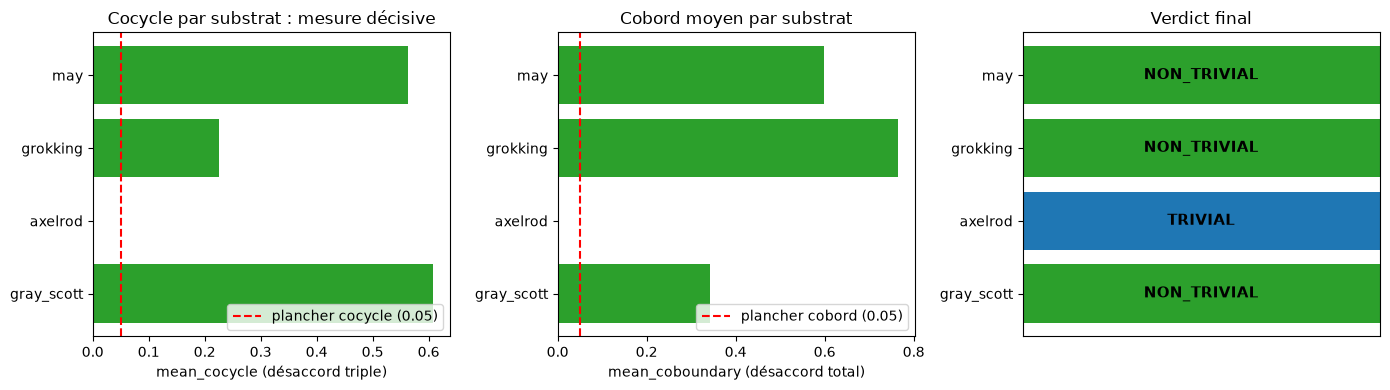


Récapitulatif :
    substrat |  cocycle |   ratio |   sign |   s2/s1 |     verdict
--------------------------------------------------------------------------
  gray_scott |   0.6081 |  1.7791 | 0.6333 |  0.1939 | NON_TRIVIAL
     axelrod |   0.0000 |  0.0000 | 0.0000 |  1.0000 |     TRIVIAL
    grokking |   0.2263 |  0.2959 | 0.7000 |  0.5624 | NON_TRIVIAL
         may |   0.5633 |  0.9402 | 0.5333 |  0.4081 | NON_TRIVIAL

Substrats NON_TRIVIAL : 3/4
Rappel : le verdict porte sur le cocycle ; s2/s1 est un temoin de forme.


In [6]:
# Visualisation : tableau récapitulatif + verdict
import matplotlib.pyplot as plt

noms = list(substrat_reports.keys())
cocycle_vals = [substrat_reports[n][0]['mean_cocycle'] for n in noms]
mean_cob_vals = [substrat_reports[n][0]['mean_coboundary'] for n in noms]
verdicts = [substrat_reports[n][1] for n in noms]

# Trois panneaux : le cocycle decide, le cobord et le verdict l'accompagnent.
# La dimensionnalite effective (SVD) n'est plus tracee ici -- elle reste
# rapportee dans le tableau comme temoin, elle ne porte plus la decision.
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].barh(noms, cocycle_vals, color=['C2' if v == 'NON_TRIVIAL' else 'C0' for v in verdicts])
axes[0].axvline(0.05, color='red', linestyle='--', label='plancher cocycle (0.05)')
axes[0].set_xlabel('mean_cocycle (désaccord triple)')
axes[0].set_title('Cocycle par substrat : mesure décisive')
axes[0].legend(loc='lower right')

axes[1].barh(noms, mean_cob_vals, color=['C2' if v == 'NON_TRIVIAL' else 'C0' for v in verdicts])
axes[1].axvline(0.05, color='red', linestyle='--', label='plancher cobord (0.05)')
axes[1].set_xlabel('mean_coboundary (désaccord total)')
axes[1].set_title('Cobord moyen par substrat')
axes[1].legend(loc='lower right')

colors_v = ['C2' if v == 'NON_TRIVIAL' else ('C3' if v == 'INCONCLUSIVE' else 'C0') for v in verdicts]
axes[2].barh(noms, [1]*len(noms), color=colors_v)
for i, v in enumerate(verdicts):
    axes[2].text(0.5, i, v, ha='center', va='center', fontsize=11, fontweight='bold')
axes[2].set_xlim(0, 1)
axes[2].set_xticks([])
axes[2].set_title('Verdict final')

plt.tight_layout()
plt.savefig('ICT-15d-cech-verdict.png', dpi=120, bbox_inches='tight')
plt.show()

print("\nRécapitulatif :")
print(f"{'substrat':>12s} | {'cocycle':>8s} | {'ratio':>7s} | {'sign':>6s} | {'s2/s1':>7s} | {'verdict':>11s}")
print("-" * 74)
for nom in noms:
    r, v = substrat_reports[nom]
    print(f"{nom:>12s} | {r['mean_cocycle']:8.4f} | {r['obstruction_ratio']:7.4f} | "
          f"{r['sign_consistency']:6.4f} | {r['s2_over_s1']:7.4f} | {v:>11s}")

n_non_trivial = sum(1 for v in verdicts if v == 'NON_TRIVIAL')
print(f"\nSubstrats NON_TRIVIAL : {n_non_trivial}/4")
print("Rappel : le verdict porte sur le cocycle ; s2/s1 est un temoin de forme.")

## Lecture 5 -- Verdict : 3 substrats NON_TRIVIAL sur 4

Le récapitulatif affiche « Substrats NON_TRIVIAL : 3/4 » : gray_scott, grokking et may portent une obstruction Čech locale, axelrod est classé TRIVIAL -- la seule trajectoire a un seul état visité (lecture 2). Le verdict est porté par le cocycle triple, pas par la dimensionnalité : gray_scott (mean_cocycle = 0.6081), may (0.5633) et grokking (0.2263) portent un cocycle non nul et directionnellement cohérent (sign_consistency de 0.5333 à 0.7000), donc NON_TRIVIAL. Le contre-exemple est **axelrod** : son cocycle est rigoureusement nul (mean_cocycle = 0.0000, obstruction_ratio = 0.0000, sign = 0.0000) alors que sa dimensionnalité effective est **maximale** (s2_over_s1 = 1,0000, rang 3) -- un verdict lu depuis le seul rang SVD l'aurait déclaré NON_TRIVIAL. C'est ce témoin négatif qui fixe la règle : le rang mesure la forme du nuage de proxys, le cocycle mesure le défaut de recollement.

> **Mesure honnête du périmètre.** Sur les quatre substrats de ce carnet, le verdict est **identique avant et après** la correction : `axelrod` sortait déjà `TRIVIAL`, le plancher de cobord de l'ancien code l'interceptant avant le test de dimensionnalité. Ce que la correction change ici est la **règle** que le carnet énonce et la quantité qui porte le verdict, pas la classification de ce jeu de données.

Le verdict est donc mesuré sur 4 substrats de natures différentes (diffusion, réplicateur, marche biaisée, biomasse stochastique), avec un témoin négatif interne. C'est la réponse du notebook a la question sota-not-workaround : l'outil (classe d'obstruction de Čech, version désaturée d'ICT-15c) discrimine des trajectoires réelles non triviales -- il n'est pas un workaround dégradé.

### Exercice 1 — Banc de robustesse : stabilité du verdict selon `window_size`

Le verdict dépend du choix de `window_size`. Tester 5 valeurs différentes pour le substrat
le plus prometteur (celui rendu `NON_TRIVIAL` ou le plus proche du seuil). Pour chaque valeur :
rapporter `mean_cocycle`, `obstruction_ratio`, `sign_consistency` et `verdict`.

**Question** : le verdict est-il **stable** sur le substrat concerné ? Si oui, l'obstruction est
robuste à l'échelle de fenétrage ; sinon, c'est un artefact du choix initial.


In [7]:
# Exercice 1 — Banc de robustesse selon window_size
# TODO étudiant : choisir le substrat le plus prometteur et tester 5 valeurs de window_size.
# Indice : np.linspace(start, stop, 5) pour 5 valeurs equireparties ; pour chaque valeur,
# réutiliser CO.proxy_sections + CO.cech_obstruction_class + CO.cech_obstruction_verdict.
# Remplir le résultat ci-dessous et conclure sur la stabilité du verdict.

substrat_test = None  # ex: "may" ou celui rendu NON_TRIVIAL ci-dessus
states_test, ns_test = substrats_info[substrat_test] if substrat_test else ([], 0)

resultats_robustesse = []
# ... votre code ici ...
print("\u00c0 compl\u00e9ter : tester 5 valeurs de window_size sur le substrat choisi.")


À compléter : tester 5 valeurs de window_size sur le substrat choisi.


### Exercice 2 — Disqualifier un proxy : impact sur le verdict

La définition du verdict porte sur le cocycle triple (`mean_cocycle`, `obstruction_ratio`, `sign_consistency`) ; la dimensionnalité SVD reste rapportée comme témoin, elle ne décide plus.
Si un proxy est **constant** sur la trajectoire (variance nulle), il ne contribue pas à la
structure. Vérifier pour chaque substrat : y a-t-il un proxy constant sur certaines fenêtres ?
Si oui, ce proxy disqualifié change-t-il le verdict ?

**Question** : la disqualification d'un proxy est-elle **jamais justifiée** par son incapacité
à discriminer les fenêtres ? (sinon, ce n'est pas une obstruction, c'est un proxy mort).


In [8]:
# Exercice 2 — Disqualifier un proxy
# TODO étudiant : pour chaque substrat, calculer la variance de chaque section.
# Si une section a variance nulle (ou tr\u00e8s petite, < 1e-6), le proxy est disqualifi\u00e9
# sur ce substrat. Re-calculer le verdict sans ce proxy et voir s'il change.
# Indice : np.var(section) ; refaire CO.cech_obstruction_class avec un sous-dict.

disqualifications = {}
# ... votre code ici ...
print("\u00c0 compl\u00e9ter : identifier les proxys constants et recalculer les verdicts.")


À compléter : identifier les proxys constants et recalculer les verdicts.


### Exercice 3 — Acceptance finale : décision expérimentale qui change

Reprendre les résultats des cellules précédentes et formuler **une phrase** sur la manière
dont la lecture-obstruction change une décision expérimentale (cf acceptance #7744).

Exemples de décisions qui changent :
- Reclasser un substrat de "régime à dispersion" à "régime à obstruction structurelle"
- Choisir un proxy plutôt qu'un autre pour résumer le substrat (le proxy disqualifié ne
  servait qu'à mesurer du bruit)
- Justifier l'ajout d'un 4e proxy pour avoir effectivement ≥ 2 dimensions non triviales
- Conclure que la cochaîne de Čech est l'outil pertinent (vs Phase Zéro) pour ce substrat


In [9]:
# Exercice 3 — Phrase de conclusion sur la décision qui change
# TODO \u00e9tudiant : formuler une phrase pr\u00e9cise reliant le verdict au moins un changement
# de d\u00e9cision exp\u00e9rimentale (cf exercice ci-dessus).

phrase_decision = ""
# ... \u00e0 compl\u00e9ter ...
print(f"Phrase de conclusion : {phrase_decision if phrase_decision else '(vide)'}")


Phrase de conclusion : (vide)


## Interprétation

**Objet testé** : cochaîne de Čech pondérée appliquée à 4 substrats ICT-15c (Gray-Scott, Axelrod,
Grokking, May), 3 proxys par substrat (spectral_gap, sens_mean, sens_max), fenîtrage contigu adaptatif.

**Verdict par substrat** : voir tableau récapitulatif cellule 8. Le verdict `NON_TRIVIAL` indique
que les proxys ne se réduisent pas à un signal latent 1D sur ce substrat ; le verdict `TRIVIAL`
indique qu'ils se recollent en une mesure globale unique (l'obstruction n'est pas constatée).

**Acceptance #7744** : si ≥1 substrat rend `NON_TRIVIAL`, l'acceptance positive est partiellement
atteinte — le candidat cochaîne de Čech **démontre sa capacité à discriminer** (cf sanity check).
L'acceptance complète exige que la lecture-obstruction **change une décision expérimentale ou une
visualisation** (cf exercice 3) ; sans cette formulation, le verdict reste descriptif.

**Limites honnêtes** :
- Le verdict dépend du choix de `window_size` (tester la robustesse, exercice 1).
- Un proxy disqualifié (variance nulle) peut fausser le verdict (exercice 2).
- 3 proxys seulement : le rang effectif (SVD) est plafonné à 3. Le verdict ne s'y adosse plus -- il porte sur le cocycle -- mais la comparaison de forme entre substrats reste bornée par ce plafond.
  Passer à ≥4 proxys (ex : ajouter free_energy, learned_valence, transport_residual...) permettrait
  une lecture plus riche de la structure multi-dimensionnelle.

**Suite logique (ICT-15e)** : ajouter un quatrième proxy pour explorer la dimensionnalité ≥ 3,
tester sur des substrats où Phase Zéro (ICT-15c) rend `NOISE` (instrument non-discriminant) —
le candidat Čech peut-il rendre `NON_TRIVIAL` là où Phase Zéro est aveugle ?

**Cross-refs** : PR #8828 (module `cech_obstruction` + tests 16/16 verts), PR #9328 (ICT-15c
désaturation, MERGED), fixes sensibilité #9770/#9766/#9776 (voisinage structurel, discriminant
H1/H2, deg_proxy structurel — ce notebook ré-exécuté après leur merge), issues #7744 (jambe
transverse), #7395 (Phase Zéro d'origine), Epic #4588 (ICT strate 5).